<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/susy_qm/susyqm_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Quantum Mechanics* — `susyqm_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SUSYQM Ch 1 Figures — Colab Notebook
**Supersymmetric Quantum Mechanics · Chapter 1: Introducing SUSY QM**

| Figure | Section | Content |
|--------|---------|---------|
| fig01  | §1.1   | SUSY algebra & energy spectrum — bosonic/fermionic pairing diagram |
| fig02  | §1.2   | Superpotential h(x) and V(x) — quadratic, cubic, quartic examples |
| fig03  | §1.2.1 | Exact ground state wavefunctions ψ = e^{-h} on double/triple well |
| fig04  | §1.2.2 | Witten index — broken vs unbroken SUSY illustration |
| fig05  | §1.3   | SUSY action: bosonic and fermionic degrees of freedom schematic |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import os

BG    = '#1e1e2e'
FG    = '#cdd6f4'
EDGE  = '#45475a'
PURP  = '#c792ea'
BLUE  = '#7ec8e3'
YELL  = '#f9c74f'
GREEN = '#90ee90'
RED   = '#e07070'
ORAN  = '#e8a838'
TEAL  = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': PURP, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

OUTDIR = 'figures/ch01'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete — SUSYQM Ch 1 figures.')


Setup complete — SUSYQM Ch 1 figures.


  saved -> figures/ch01/fig01_susy_algebra.png


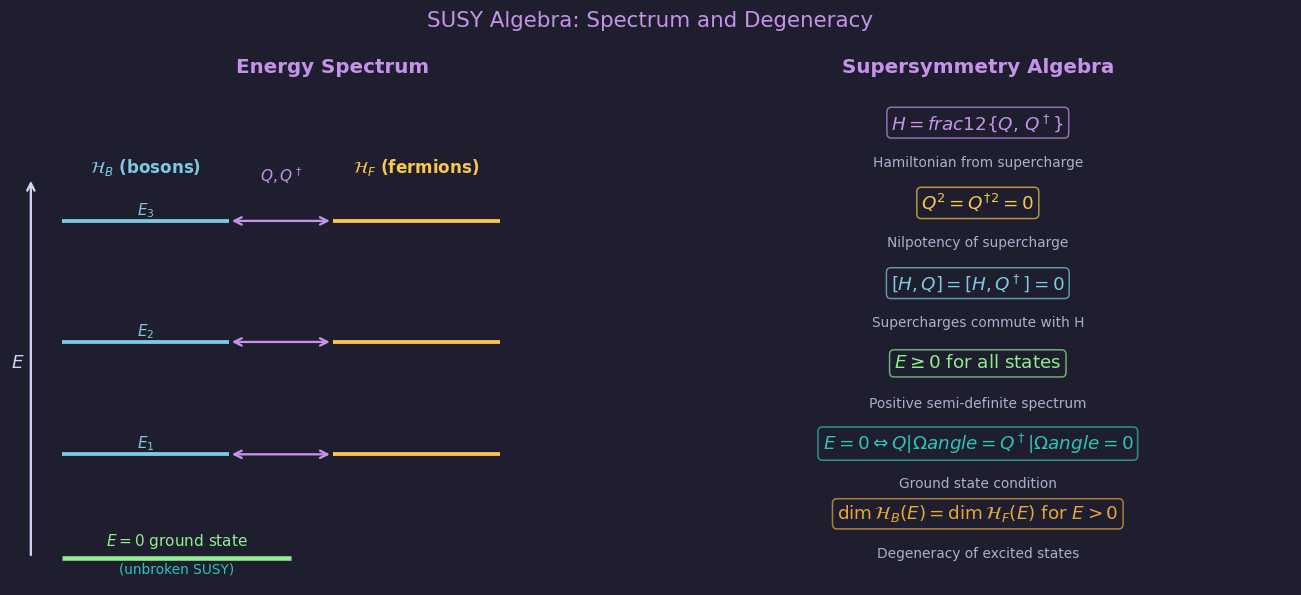

In [2]:
# ── Figure 1: SUSY algebra and energy spectrum ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('SUSY Algebra: Spectrum and Degeneracy', color=PURP, fontsize=14)

# Left: energy level diagram
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title('Energy Spectrum', color=PURP)
ax.set_xlim(0, 3); ax.set_ylim(-0.3, 5.5)
ax.axis('off')

energies = [0, 1.2, 2.5, 3.9]
labels_B = [r'$|\Omega\rangle_{B}$', r'$E_1\,|B_1\rangle$',
            r'$E_2\,|B_2\rangle$', r'$E_3\,|B_3\rangle$']
labels_F = [r'$E_1\,|F_1\rangle$', r'$E_2\,|F_2\rangle$',
            r'$E_3\,|F_3\rangle$']

# Ground state (could be B or F — show as special)
ax.hlines(0, 0.2, 1.3, colors=GREEN, linewidths=3)
ax.text(0.75, 0.08, r'$E=0$ ground state', ha='center', va='bottom',
        fontsize=10, color=GREEN)
ax.text(0.75, -0.18, r'(unbroken SUSY)', ha='center', fontsize=9, color=TEAL)

# Paired levels
for i, E in enumerate(energies[1:], start=1):
    # Bosonic level (left column)
    ax.hlines(E, 0.2, 1.0, colors=BLUE, linewidths=2.5)
    ax.text(0.6, E+0.07, f'$E_{i}$', ha='center', fontsize=10, color=BLUE)
    # Fermionic level (right column)
    ax.hlines(E, 1.5, 2.3, colors=YELL, linewidths=2.5)
    # Arrow connecting pair
    ax.annotate('', xy=(1.5, E), xytext=(1.0, E),
                arrowprops=dict(arrowstyle='<->', color=PURP, lw=1.5))

ax.text(0.6, 4.45, r'$\mathcal{H}_B$ (bosons)', ha='center', fontsize=11,
        color=BLUE, fontweight='bold')
ax.text(1.9, 4.45, r'$\mathcal{H}_F$ (fermions)', ha='center', fontsize=11,
        color=YELL, fontweight='bold')
ax.text(1.25, 4.35, r'$Q,Q^\dagger$', ha='center', fontsize=10, color=PURP)

# y-axis arrow
ax.annotate('', xy=(0.05, 4.4), xytext=(0.05, 0),
            arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
ax.text(0.02, 2.2, r'$E$', ha='right', fontsize=12, color=FG)

# Right: algebraic relations
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_title('Supersymmetry Algebra', color=PURP)
ax2.axis('off')

relations = [
    (0.5, 0.88, r'$H = \frac{1}{2}\{Q,\,Q^\dagger\}$',
     'Hamiltonian from supercharge', PURP),
    (0.5, 0.72, r'$Q^2 = Q^{\dagger 2} = 0$',
     'Nilpotency of supercharge', YELL),
    (0.5, 0.56, r'$[H, Q] = [H, Q^\dagger] = 0$',
     'Supercharges commute with H', BLUE),
    (0.5, 0.40, r'$E \geq 0$ for all states',
     'Positive semi-definite spectrum', GREEN),
    (0.5, 0.24, r'$E=0 \Leftrightarrow Q|\Omega\rangle = Q^\dagger|\Omega\rangle=0$',
     'Ground state condition', TEAL),
    (0.5, 0.10, r'$\dim\mathcal{H}_B(E) = \dim\mathcal{H}_F(E)$ for $E>0$',
     'Degeneracy of excited states', ORAN),
]
for x, y, eq, desc, col in relations:
    ax2.text(x, y+0.04, eq, ha='center', va='center',
             fontsize=12, color=col, transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=col, alpha=0.7))
    ax2.text(x, y-0.04, desc, ha='center', va='center',
             fontsize=9, color=FG, alpha=0.8, transform=ax2.transAxes)

plt.tight_layout()
save('fig01_susy_algebra.png', fig)


  saved -> figures/ch01/fig02_superpotential.png


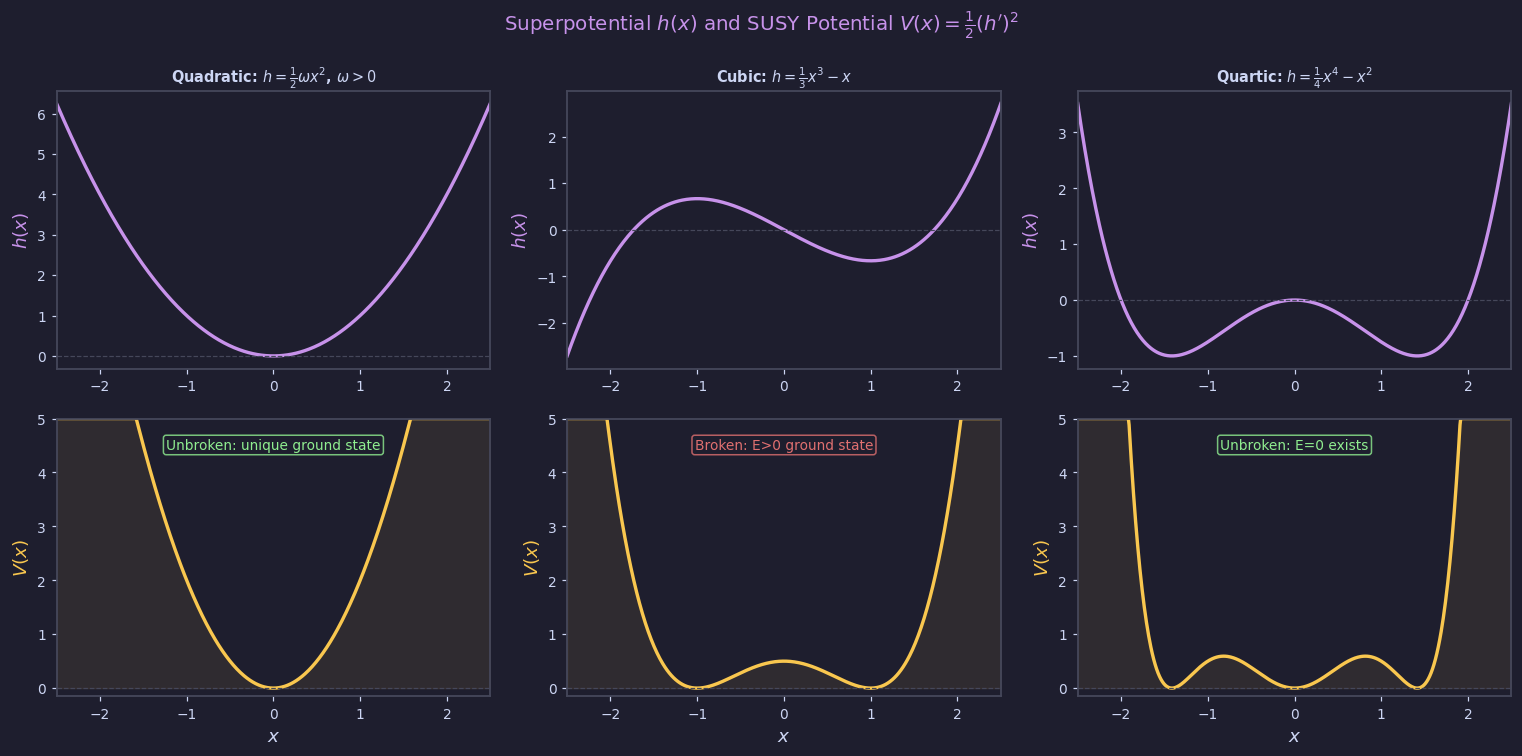

In [3]:
# ── Figure 2: Superpotential h(x) and V(x) = (h')^2/2 ─────────────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
fig.suptitle(r"Superpotential $h(x)$ and SUSY Potential $V(x)=\frac{1}{2}(h')^2$",
             color=PURP, fontsize=13)

x = np.linspace(-2.5, 2.5, 600)
cases = [
    # (label, h(x), omega_sign, SUSY status)
    (r'Quadratic: $h=\frac{1}{2}\omega x^2$, $\omega>0$',
     0.5*2*x**2, lambda x: 2*x, 'Unbroken: unique ground state'),
    (r'Cubic: $h=\frac{1}{3}x^3 - x$',
     x**3/3 - x, lambda x: x**2 - 1, 'Broken: E>0 ground state'),
    (r'Quartic: $h=\frac{1}{4}x^4 - x^2$',
     x**4/4 - x**2, lambda x: x**3 - 2*x, 'Unbroken: E=0 exists'),
]

for col, (title, h, hp_fn, status) in enumerate(cases):
    hp = hp_fn(x)
    V  = 0.5 * hp**2

    ax_h = axes[0, col]
    ax_V = axes[1, col]

    ax_h.plot(x, h, color=PURP, lw=2.2, label=r'$h(x)$')
    ax_h.axhline(0, color=EDGE, lw=0.8, ls='--')
    ax_h.set_title(title, color=FG, fontsize=9.5)
    ax_h.set_ylabel(r'$h(x)$', color=PURP)
    ax_h.tick_params(labelsize=9)
    ax_h.set_xlim(-2.5, 2.5)

    Vclip = np.clip(V, 0, 5)
    ax_V.plot(x, Vclip, color=YELL, lw=2.2, label=r'$V(x)$')
    ax_V.fill_between(x, 0, Vclip, color=YELL, alpha=0.08)
    ax_V.axhline(0, color=EDGE, lw=0.8, ls='--')
    ax_V.set_ylabel(r'$V(x)$', color=YELL)
    ax_V.set_xlabel(r'$x$')
    ax_V.tick_params(labelsize=9)
    ax_V.set_xlim(-2.5, 2.5); ax_V.set_ylim(-0.15, 5)

    color_status = GREEN if 'Unbroken' in status else RED
    ax_V.text(0.5, 0.93, status, transform=ax_V.transAxes,
              ha='center', va='top', fontsize=9, color=color_status,
              bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=color_status, alpha=0.8))

for ax in axes.flat:
    ax.set_facecolor(BG)

plt.tight_layout()
save('fig02_superpotential.png', fig)


  saved -> figures/ch01/fig03_ground_states.png


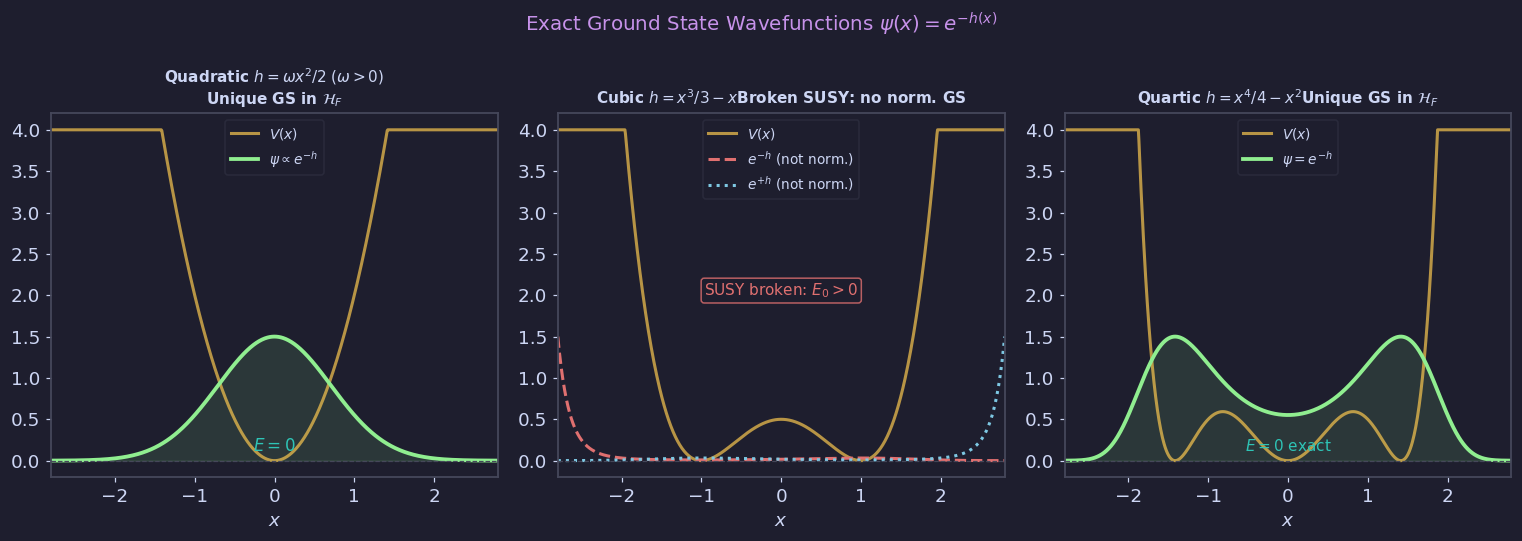

In [4]:
# ── Figure 3: Exact ground state ψ = e^{-h} ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle(r'Exact Ground State Wavefunctions $\psi(x) = e^{-h(x)}$',
             color=PURP, fontsize=13)

x = np.linspace(-2.8, 2.8, 800)

# Case 1: Quadratic — single well, unique GS in H_F
h1  = 0.5 * 2 * x**2
V1  = 0.5 * (2*x)**2
psi1 = np.exp(-h1)
psi1 /= psi1.max()

ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'Quadratic $h=\omega x^2/2$'+r'$\;(\omega>0)$'+
             '\nUnique GS in '+r'$\mathcal{H}_F$', color=FG, fontsize=10)
ax.plot(x, np.clip(V1, 0, 4), color=YELL, lw=2, label=r'$V(x)$', alpha=0.7)
ax.plot(x, psi1*1.5, color=GREEN, lw=2.5, label=r'$\psi\propto e^{-h}$')
ax.fill_between(x, 0, psi1*1.5, color=GREEN, alpha=0.12)
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.2, 4.2)
ax.legend(fontsize=9, loc='upper center')
ax.text(0, 0.12, r'$E=0$', ha='center', fontsize=11, color=TEAL)

# Case 2: Cubic — broken SUSY, NO normalisable GS
h2  = x**3/3 - x
hp2 = x**2 - 1
V2  = 0.5 * hp2**2
psi2_F = np.exp(-h2)
psi2_B = np.exp(+h2)

ax = axes[1]
ax.set_facecolor(BG)
ax.set_title(r'Cubic $h=x^3/3-x$'+'Broken SUSY: no norm. GS', color=FG, fontsize=10)
ax.plot(x, np.clip(V2, 0, 4), color=YELL, lw=2, label=r'$V(x)$', alpha=0.7)
ax.plot(x, np.clip(psi2_F/psi2_F.max(), -0.5, 1.5)*1.5, color=RED,
        lw=2, ls='--', label=r'$e^{-h}$ (not norm.)')
ax.plot(x, np.clip(psi2_B/psi2_B.max(), -0.5, 1.5)*1.5, color=BLUE,
        lw=2, ls=':', label=r'$e^{+h}$ (not norm.)')
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.2, 4.2)
ax.legend(fontsize=9, loc='upper center')
ax.text(0, 2.0, r'SUSY broken: $E_0>0$', ha='center', fontsize=10, color=RED,
        bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=RED, alpha=0.8))

# Case 3: Quartic — three wells, exact GS localised on outer wells
h3  = x**4/4 - x**2
hp3 = x**3 - 2*x
V3  = 0.5 * hp3**2
psi3 = np.exp(-h3)
psi3 /= psi3.max()

ax = axes[2]
ax.set_facecolor(BG)
ax.set_title(r'Quartic $h=x^4/4-x^2$'+''+r'Unique GS in $\mathcal{H}_F$',
             color=FG, fontsize=10)
ax.plot(x, np.clip(V3, 0, 4), color=YELL, lw=2, label=r'$V(x)$', alpha=0.7)
ax.plot(x, psi3*1.5, color=GREEN, lw=2.5, label=r'$\psi = e^{-h}$')
ax.fill_between(x, 0, psi3*1.5, color=GREEN, alpha=0.12)
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
ax.set_xlim(-2.8, 2.8); ax.set_ylim(-0.2, 4.2)
ax.legend(fontsize=9, loc='upper center')
ax.text(0, 0.12, r'$E=0$ exact', ha='center', fontsize=10, color=TEAL)

for ax in axes:
    ax.set_xlabel(r'$x$')

plt.tight_layout()
save('fig03_ground_states.png', fig)


  saved -> figures/ch01/fig04_witten_index.png


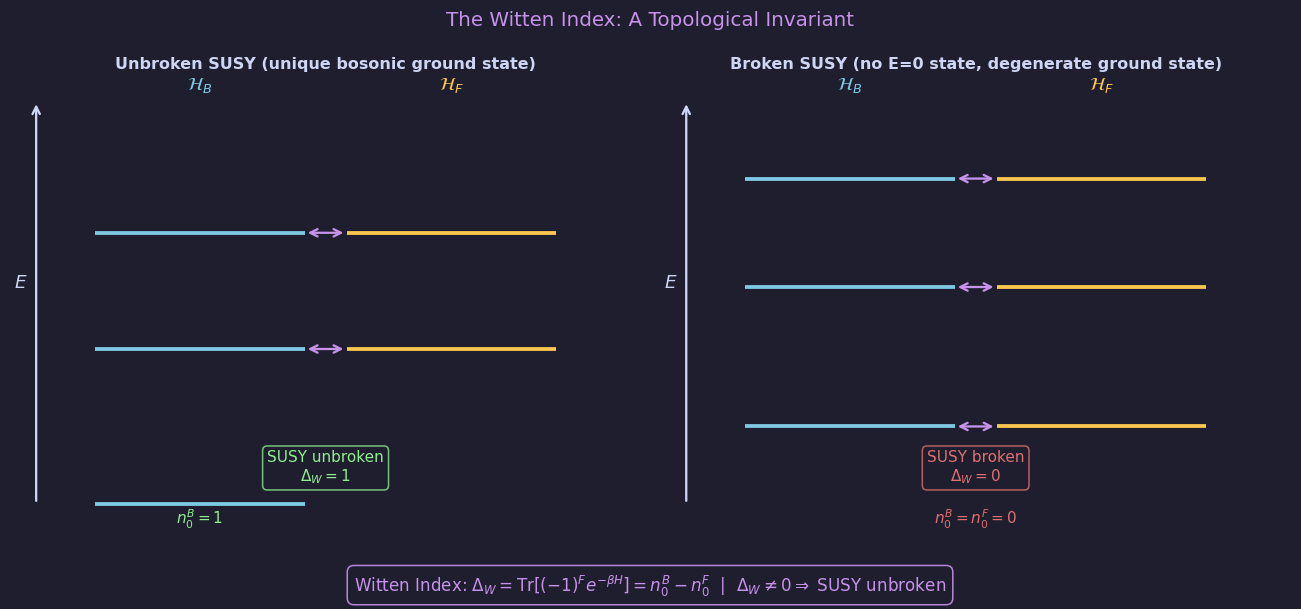

In [5]:
# ── Figure 4: Witten Index ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('The Witten Index: A Topological Invariant', color=PURP, fontsize=13)

def draw_spectrum(ax, title, energies_B, energies_F, E0_sector=None,
                  witten_idx=None, susy_status='unbroken'):
    ax.set_facecolor(BG)
    ax.set_title(title, color=FG, fontsize=10.5)
    ax.set_xlim(0, 3); ax.set_ylim(-0.4, 5.5)
    ax.axis('off')

    # y-axis arrow
    ax.annotate('', xy=(0.12, 5.2), xytext=(0.12, 0),
                arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
    ax.text(0.08, 2.8, r'$E$', ha='right', fontsize=12, color=FG)

    # Column headers
    ax.text(0.9,  5.35, r'$\mathcal{H}_B$', ha='center', fontsize=12,
            color=BLUE, fontweight='bold')
    ax.text(2.1,  5.35, r'$\mathcal{H}_F$', ha='center', fontsize=12,
            color=YELL, fontweight='bold')

    for E in energies_B:
        ax.hlines(E, 0.4, 1.4, colors=BLUE, linewidths=2.5)
    for E in energies_F:
        ax.hlines(E, 1.6, 2.6, colors=YELL, linewidths=2.5)

    # Arrows for paired levels
    common = sorted(set(energies_B) & set(energies_F))
    for E in common:
        ax.annotate('', xy=(1.6, E), xytext=(1.4, E),
                    arrowprops=dict(arrowstyle='<->', color=PURP, lw=1.5))

    # Ground state annotation
    if E0_sector == 'B':
        ax.text(0.9, -0.25, r'$n_0^B=1$', ha='center', fontsize=10, color=GREEN)
    elif E0_sector == 'F':
        ax.text(2.1, -0.25, r'$n_0^F=1$', ha='center', fontsize=10, color=GREEN)
    else:
        ax.text(1.5, -0.25, r'$n_0^B=n_0^F=0$', ha='center', fontsize=10, color=RED)

    col = GREEN if susy_status == 'unbroken' else RED
    delta_part = r'$\Delta_W = ' + str(witten_idx) + r'$' if witten_idx is not None else ''
    label = f'SUSY {susy_status}\n{delta_part}'
    ax.text(1.5, 0.3, label, ha='center', fontsize=10, color=col,
            bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=col, alpha=0.8))

draw_spectrum(axes[0],
              'Unbroken SUSY (unique bosonic ground state)',
              energies_B=[0, 2.0, 3.5],
              energies_F=[2.0, 3.5],
              E0_sector='B', witten_idx=1, susy_status='unbroken')

draw_spectrum(axes[1],
              'Broken SUSY (no E=0 state, degenerate ground state)',
              energies_B=[1.0, 2.8, 4.2],
              energies_F=[1.0, 2.8, 4.2],
              E0_sector=None, witten_idx=0, susy_status='broken')

# Formula box between plots
fig.text(0.5, 0.02,
         r'Witten Index: $\Delta_W = \mathrm{Tr}[(-1)^F e^{-\beta H}] = n_0^B - n_0^F$'
         '  |  '
         r'$\Delta_W \neq 0 \Rightarrow$ SUSY unbroken',
         ha='center', fontsize=11, color=PURP,
         bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=PURP, alpha=0.9))

plt.tight_layout(rect=[0, 0.08, 1, 1])
save('fig04_witten_index.png', fig)


  saved -> figures/ch01/fig05_susy_action.png


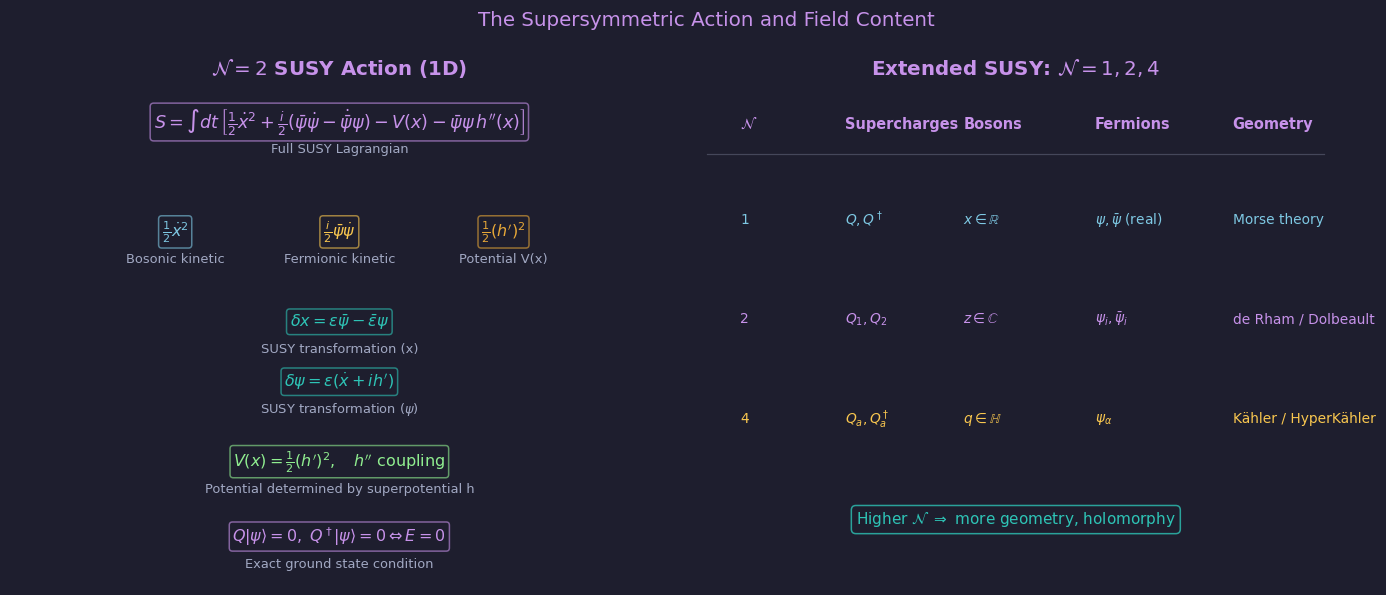

In [6]:
# ── Figure 5: SUSY action schematic and N=1,2,4 content ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('The Supersymmetric Action and Field Content', color=PURP, fontsize=13)

# Left: action terms
ax = axes[0]
ax.set_facecolor(BG)
ax.set_title(r'$\mathcal{N}=2$ SUSY Action (1D)', color=PURP)
ax.axis('off')

terms = [
    (0.5, 0.90,
     r'$S = \int dt\,\left[\frac{1}{2}\dot{x}^2 + \frac{i}{2}(\bar{\psi}\dot{\psi}'
     r' - \dot{\bar{\psi}}\psi) - V(x) - \bar{\psi}\psi\,h^{\prime\prime}(x)\right]$',
     'Full SUSY Lagrangian', PURP),
    (0.25, 0.68, r'$\frac{1}{2}\dot{x}^2$', 'Bosonic kinetic', BLUE),
    (0.5,  0.68, r'$\frac{i}{2}\bar{\psi}\dot{\psi}$', 'Fermionic kinetic', YELL),
    (0.75, 0.68, r'$\frac{1}{2}(h^\prime)^2$', 'Potential V(x)', ORAN),
    (0.5,  0.50, r'$\delta x = \epsilon\bar{\psi} - \bar{\epsilon}\psi$',
     'SUSY transformation (x)', TEAL),
    (0.5,  0.38, r'$\delta\psi = \epsilon(\dot{x}+ih^{\prime})$',
     r'SUSY transformation ($\psi$)', TEAL),
    (0.5,  0.22,
     r'$V(x) = \frac{1}{2}(h^{\prime})^2,\quad h^{\prime\prime}\text{ coupling}$',
     'Potential determined by superpotential h', GREEN),
    (0.5,  0.07,
     r'$Q|\psi\rangle=0,\;Q^\dagger|\psi\rangle=0 \Leftrightarrow E=0$',
     'Exact ground state condition', PURP),
]
for x_,y_,eq,desc,col in terms:
    fs = 11.5 if y_ > 0.85 else 10.5
    ax.text(x_, y_+0.025, eq, ha='center', va='center', fontsize=fs,
            color=col, transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.6))
    ax.text(x_, y_-0.030, desc, ha='center', va='center',
            fontsize=8.5, color=FG, alpha=0.75, transform=ax.transAxes)

# Right: SUSY multiplet content for N=1,2,4
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_title(r'Extended SUSY: $\mathcal{N}=1,2,4$', color=PURP)
ax2.axis('off')

rows = [
    (r'$\mathcal{N}$', 'Supercharges', 'Bosons', 'Fermions', 'Geometry', FG),
    ('1', r'$Q, Q^\dagger$', r'$x \in \mathbb{R}$',
     r'$\psi, \bar\psi$ (real)', 'Morse theory', BLUE),
    ('2', r'$Q_1,Q_2$', r'$z \in \mathbb{C}$',
     r'$\psi_i, \bar\psi_i$', 'de Rham / Dolbeault', PURP),
    ('4', r'$Q_a, Q_a^\dagger$', r'$q \in \mathbb{H}$',
     r'$\psi_\alpha$', 'Kähler / HyperKähler', YELL),
]
ys = [0.92, 0.73, 0.53, 0.33]
for (N, Q, bos, ferm, geom, col), y in zip(rows, ys):
    if N == r'$\mathcal{N}$':
        cols = [N, Q, bos, ferm, geom]
        xs   = [0.08, 0.24, 0.42, 0.62, 0.83]
        for xi, c in zip(xs, cols):
            ax2.text(xi, y, c, ha='left', va='center', fontsize=9.5,
                     color=PURP, fontweight='bold', transform=ax2.transAxes)
        ax2.axhline(y - 0.06, xmin=0.03, xmax=0.97, color=EDGE,
                    lw=0.8) #, transform=ax2.transAxes)
    else:
        data = [N, Q, bos, ferm, geom]
        xs   = [0.08, 0.24, 0.42, 0.62, 0.83]
        for xi, d in zip(xs, data):
            ax2.text(xi, y, d, ha='left', va='center', fontsize=9,
                     color=col, transform=ax2.transAxes)

# Bottom note on holomorphy
ax2.text(0.5, 0.12,
         r'Higher $\mathcal{N}$ $\Rightarrow$ more geometry, holomorphy',
         ha='center', fontsize=10, color=TEAL, transform=ax2.transAxes,
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=TEAL, alpha=0.8))

plt.tight_layout()
save('fig05_susy_action.png', fig)


In [7]:
import shutil
shutil.make_archive('susyqm_ch01_figures', 'zip', 'figures/ch01')
try:
    from google.colab import files
    files.download('susyqm_ch01_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch01/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
